<a href="https://colab.research.google.com/github/Kevin1077/Bank-project/blob/Data-preprocessing/Bank_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Member 1 - Saleem**

DATASET LOADING , EDA & DATA CLEANING DATASET LOADING


Import Libraries


In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

Dataset Loading

In [65]:
df_bank= pd.read_csv("/content/bank.csv", sep=";", na_values=["unknown","Unknown","UNKOWN"])

In [66]:
print("Dataset loaded successfully!")

Dataset loaded successfully!


 Initial Data Inspection

In [67]:
print("First 5 rows:")
df_bank.head()


First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,NaN,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,NaN,3,jun,199,4,-1,0,NaN,no
4,59,blue-collar,married,secondary,no,0,yes,no,NaN,5,may,226,1,-1,0,NaN,no


In [68]:
print("Last 5 rows:")
df_bank.tail()


Last 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,329,5,-1,0,NaN,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,NaN,9,may,153,1,-1,0,NaN,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,151,11,-1,0,NaN,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,129,4,211,3,other,no
4520,44,entrepreneur,single,tertiary,no,1136,yes,yes,cellular,3,apr,345,2,249,7,other,no


In [69]:
print("Dataset Shape:")
df_bank.shape

Dataset Shape:


(4521, 17)

In [70]:
print("Dataset Information:")
df_bank.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4483 non-null   object
 2   marital    4521 non-null   object
 3   education  4334 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    3197 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   816 non-null    object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [71]:
print("Statistical Summary:")
df_bank.describe()

Statistical Summary:


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [72]:
print("Missing Values:")
df_bank.isnull().sum()

Missing Values:


,0
age,0
job,38
marital,0
education,187
default,0
balance,0
housing,0
loan,0
contact,1324
day,0


In [73]:
print("missing values in %")
df_bank.isna().sum()/len(df_bank)*100

missing values in %


,0
age,0.000000
job,0.840522
marital,0.000000
education,4.136253
default,0.000000
balance,0.000000
housing,0.000000
loan,0.000000
contact,29.285556
day,0.000000


In [74]:
print("Duplicate Rows:")
df_bank.duplicated().sum()

Duplicate Rows:


np.int64(0)

 Exploratory Data Analysis (EDA)


In [75]:
print("Age Statistics:")
df_bank["age"].describe()

Age Statistics:


,age
count,4521.000000
mean,41.170095
std,10.576211
min,19.000000
25%,33.000000
50%,39.000000
75%,49.000000
max,87.000000


In [76]:
print("Balance Statistics:")
df_bank["balance"].describe()

Balance Statistics:


,balance
count,4521.000000
mean,1422.657819
std,3009.638142
min,-3313.000000
25%,69.000000
50%,444.000000
75%,1480.000000
max,71188.000000


In [77]:
print("Customers by Job:")
df_bank["job"].value_counts()

Customers by Job:


,count
job,
management,969
blue-collar,946
technician,768
admin.,478
services,417
retired,230
self-employed,183
entrepreneur,168
unemployed,128


In [78]:
print("Customers by Marital Status:")
df_bank["marital"].value_counts()

Customers by Marital Status:


,count
marital,
married,2797
single,1196
divorced,528


In [79]:
print("Term Deposit Subscription:")
df_bank["y"].value_counts()

Term Deposit Subscription:


,count
y,
no,4000
yes,521


In [80]:
print("Subscription Percentage:")
df_bank["y"].value_counts(normalize=True) * 100

Subscription Percentage:


,proportion
y,
no,88.476001
yes,11.523999


Data Visualization

In [81]:
sns.set_theme(style="whitegrid")

Visualization 1: Age Distribution

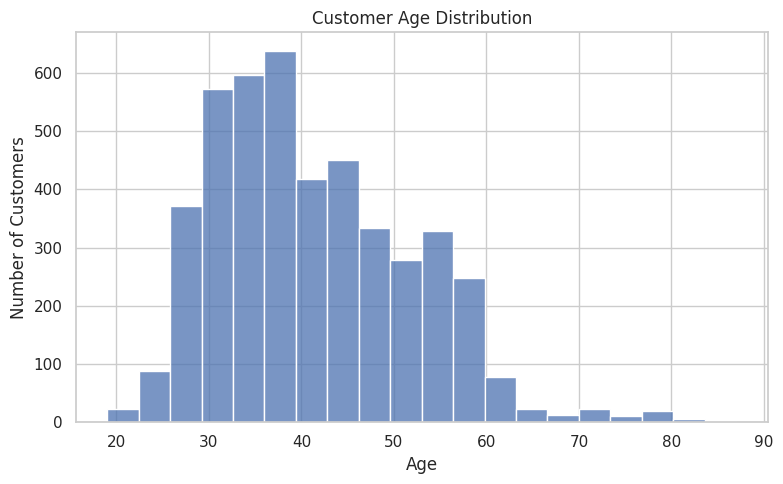

In [82]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_bank, x="age", bins=20)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


Visualization 2: Subscription Status

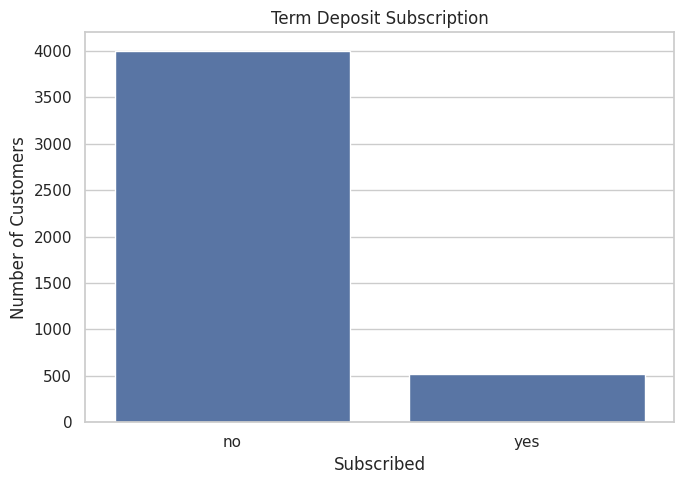

In [83]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_bank, x="y")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

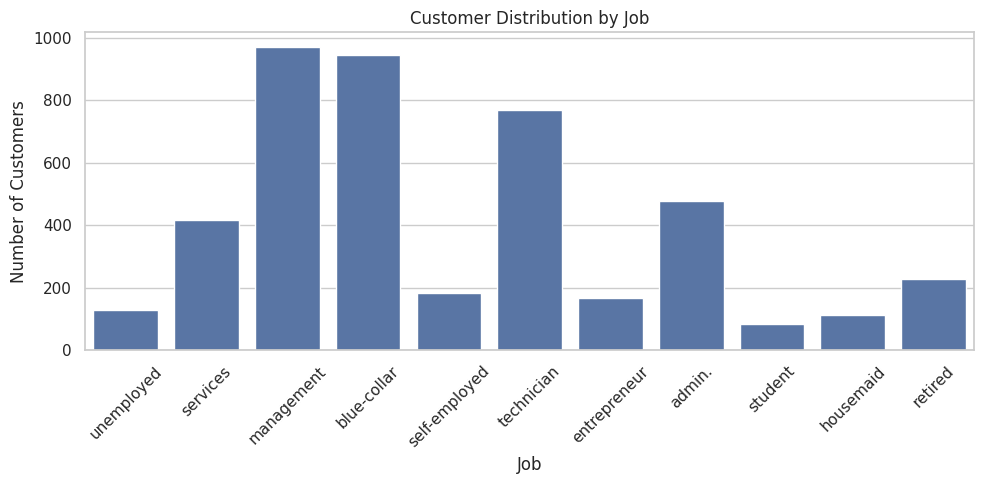

In [84]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df_bank, x="job")

plt.title("Customer Distribution by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Data Cleaning

1.Missing Value Identification


In [85]:
df_bank.isna().sum()/len(df_bank)*100


,0
age,0.000000
job,0.840522
marital,0.000000
education,4.136253
default,0.000000
balance,0.000000
housing,0.000000
loan,0.000000
contact,29.285556
day,0.000000


In [86]:
df_bank.drop(columns=['poutcome'],inplace=True)

In [87]:
columns_to_clean = ['job']

for col in columns_to_clean:
    df_bank.dropna(subset=[col], inplace=True)

#**Member 2 - Sivarenj** - Feature-Engineering-&-Statistical-Analysis

Feature Engineering

In [88]:
#new meaningful features from existing columns to improve the dataset
# Creating age groups based on customer age

df_bank["age_group"] = pd.cut(
    df_bank["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["Young", "Adult", "Middle Age","Senior", "Old", "Very Old"]
)

# Displaying the newly created age group
df_bank[["age", "age_group"]].head()

,age,age_group
0,30,Adult
1,33,Adult
2,35,Adult
3,30,Adult
4,59,Old


In [89]:
# Creating a new feature to identify previous contact status
df_bank["previously_contacted"] = np.where(
    df_bank["pdays"] == -1,
    "No",
    "Yes"
)

df_bank[["pdays", "previously_contacted"]].head()

,pdays,previously_contacted
0,-1,No
1,339,Yes
2,330,Yes
3,-1,No
4,-1,No


In [90]:
print("Newly Created Features:")
print(df_bank[["age_group", "previously_contacted"]].head())
print(df_bank.shape)

Newly Created Features:
  age_group previously_contacted
0     Adult                   No
1     Adult                  Yes
2     Adult                  Yes
3     Adult                   No
4       Old                   No
(4483, 18)


Numerical Distribution

In [91]:
# Selecting numerical columns from the dataset
num_cols = df_bank.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(list(num_cols))

Numerical Columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


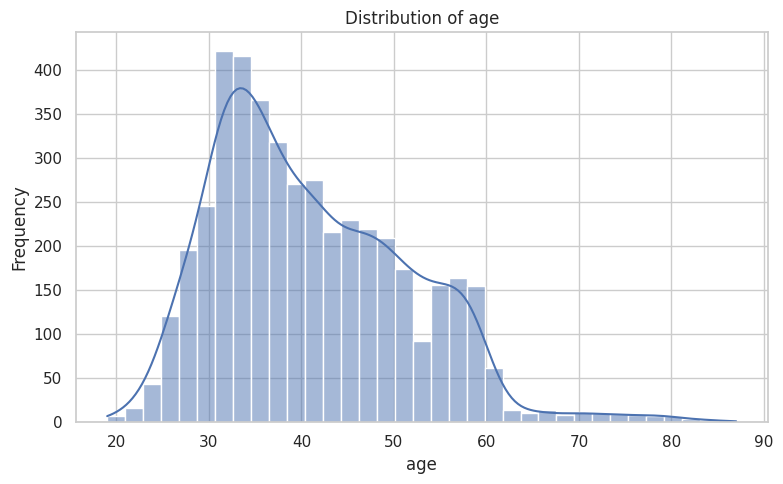

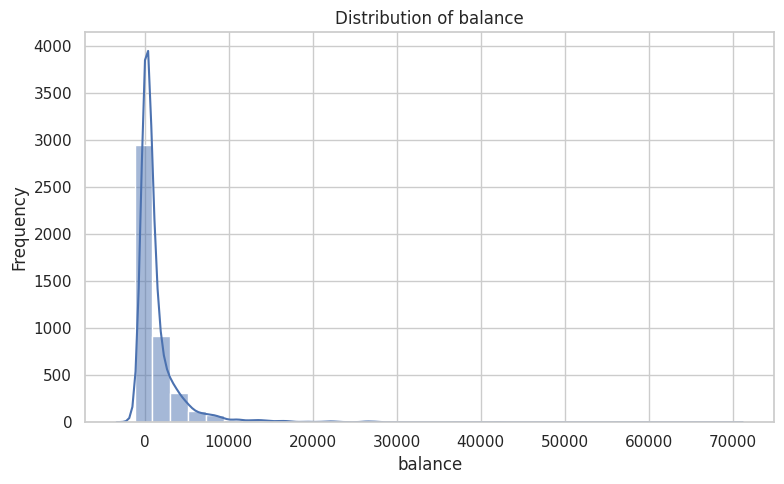

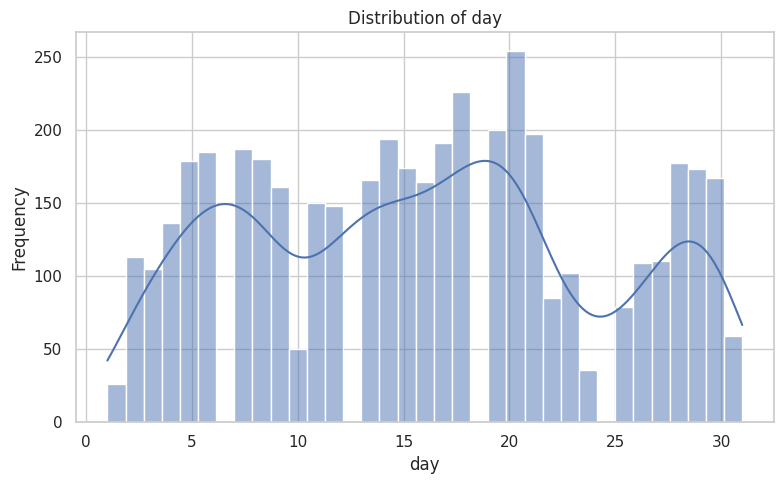

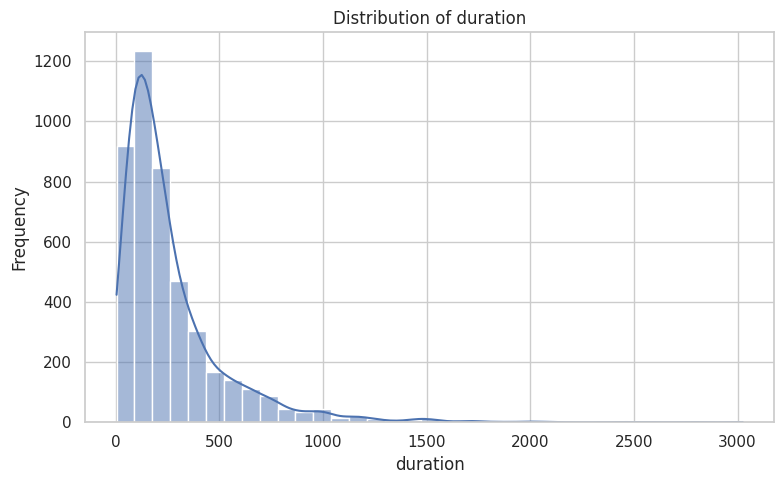

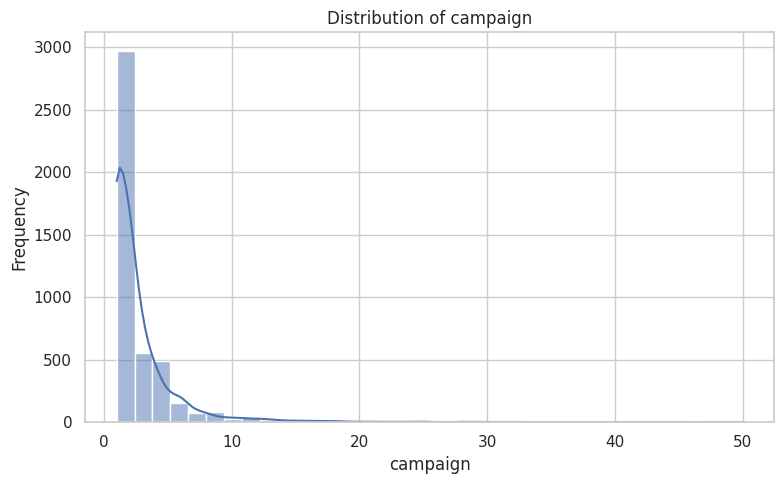

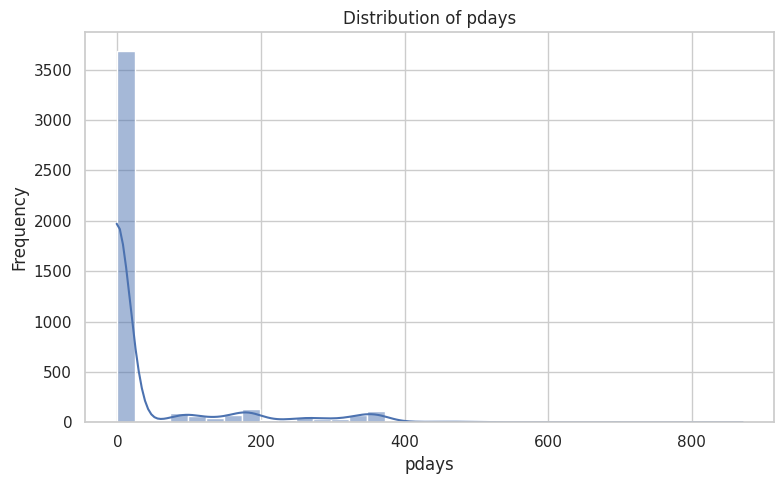

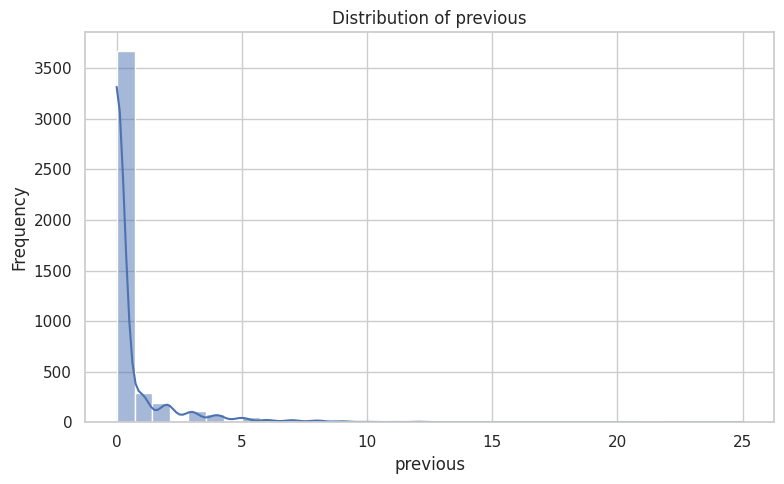

In [92]:
# Plotting histogram with KDE for all numerical columns

for col in num_cols:

    plt.figure(figsize=(8, 5))

    # Histogram with KDE curve
    sns.histplot(data=df_bank, x=col, kde=True, bins=35)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [93]:
df_bank[num_cols].skew() #Skewness Analysis

,0
age,0.707891
balance,6.599475
day,0.094865
duration,2.775434
campaign,4.746387
pdays,2.691303
previous,5.883002


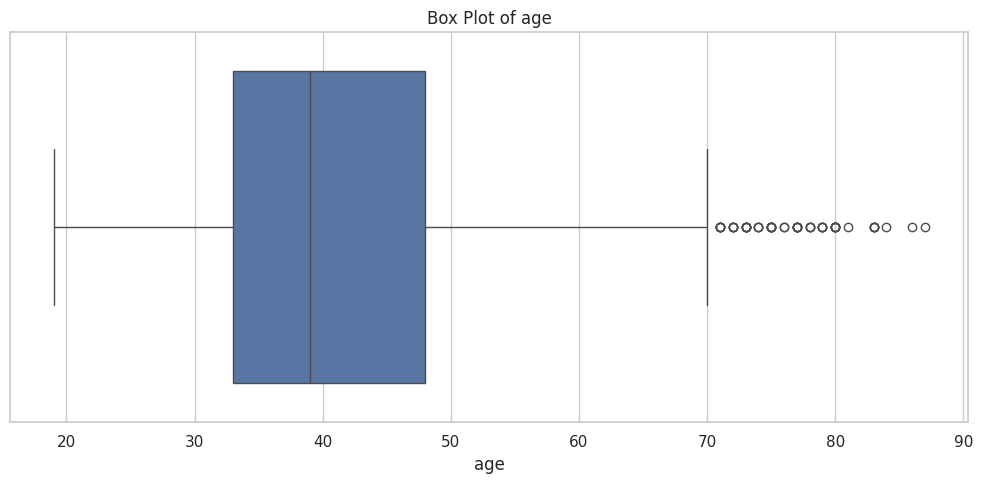

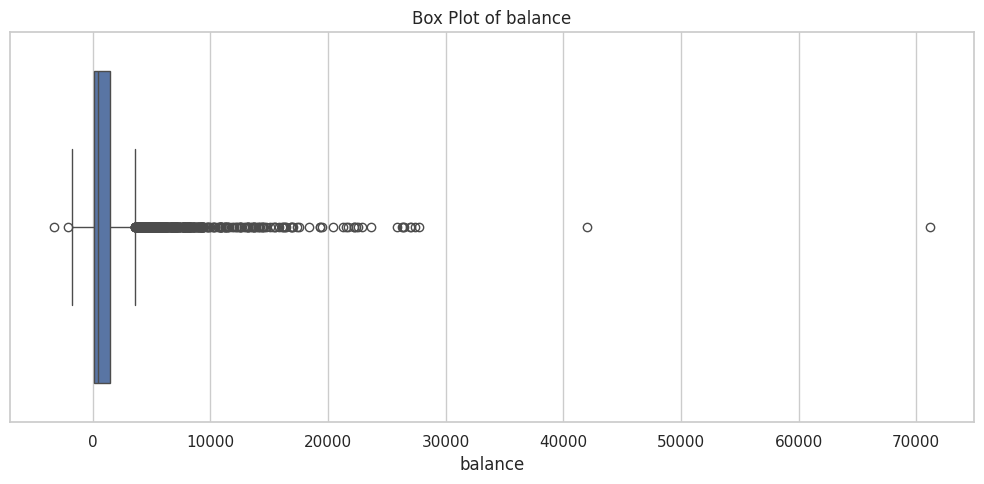

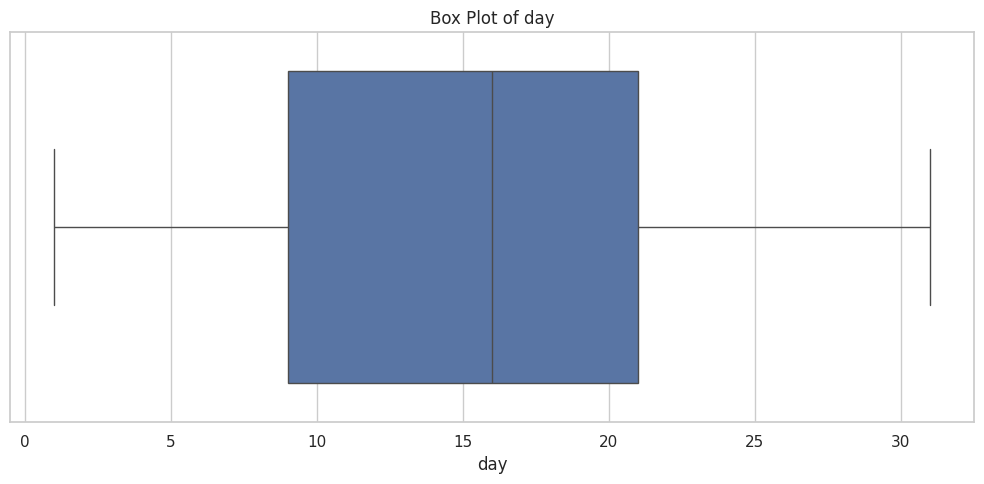

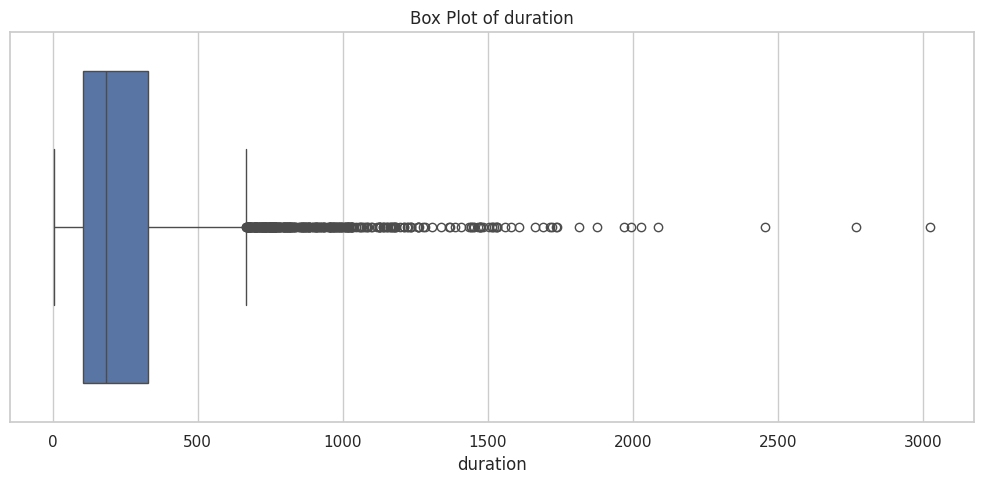

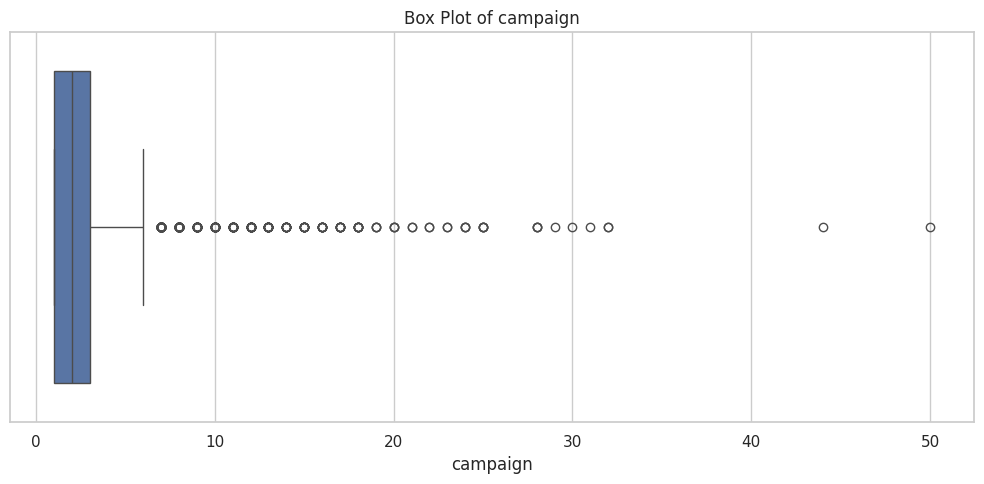

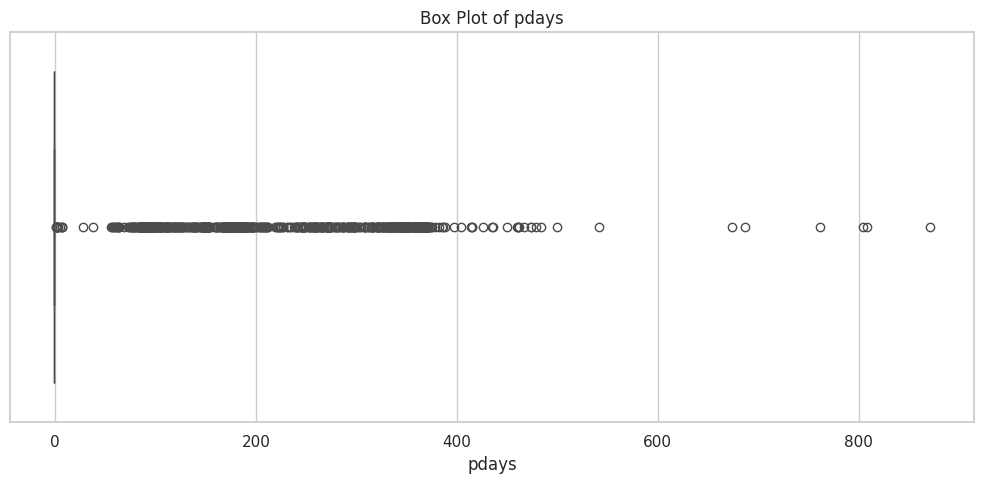

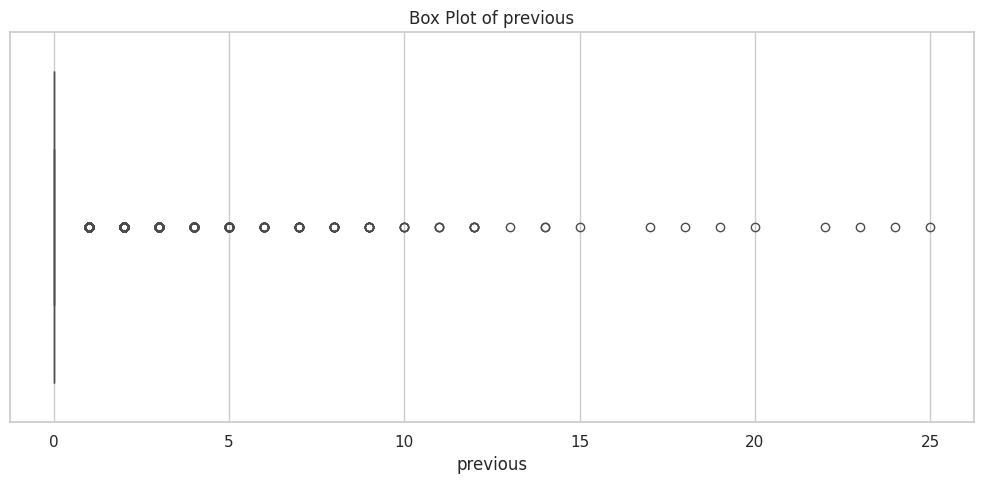

In [94]:
# Identifying outliers using box plots

for col in num_cols:

    plt.figure(figsize=(10, 5))

    # Creating box plot
    sns.boxplot(data=df_bank, x=col)

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

Categorical Analysis

In [95]:
# Selecting categorical columns from the dataset

cat_cols = df_bank.select_dtypes(include="object").columns

print("Categorical Columns:")
print(list(cat_cols))

Categorical Columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'y', 'previously_contacted']


In [96]:
# Finding the frequency of each category

for col in cat_cols:

    print("\nColumn:", col)

    # Displaying category value counts
    print(df_bank[col].value_counts())


Column: job
job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
Name: count, dtype: int64

Column: marital
marital
married     2767
single      1189
divorced     527
Name: count, dtype: int64

Column: education
education
secondary    2298
tertiary     1342
primary       671
Name: count, dtype: int64

Column: default
default
no     4407
yes      76
Name: count, dtype: int64

Column: housing
housing
yes    2558
no     1925
Name: count, dtype: int64

Column: loan
loan
no     3793
yes     690
Name: count, dtype: int64

Column: contact
contact
cellular     2872
telephone     296
Name: count, dtype: int64

Column: month
month
may    1397
jul     701
aug     623
jun     523
nov     387
apr     292
feb     221
jan     143
oct      78
sep      50
mar      48
dec      20
Name: count, dtype: int64

Column: y
y
no   

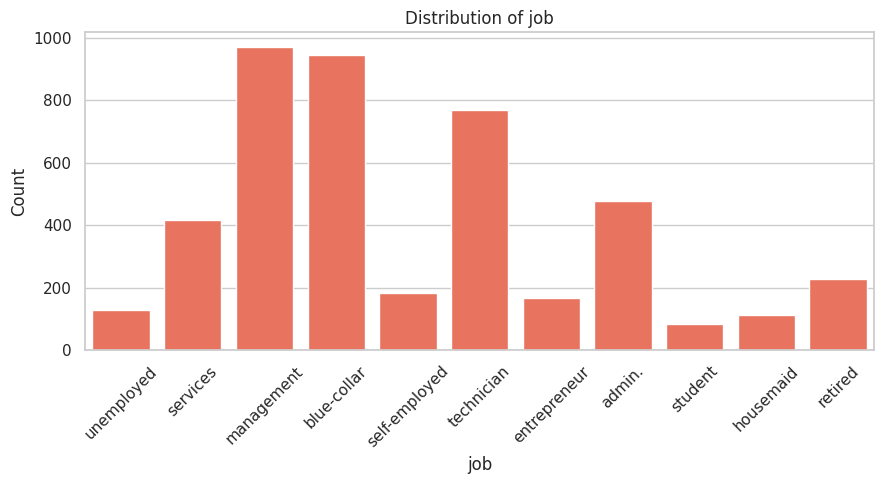

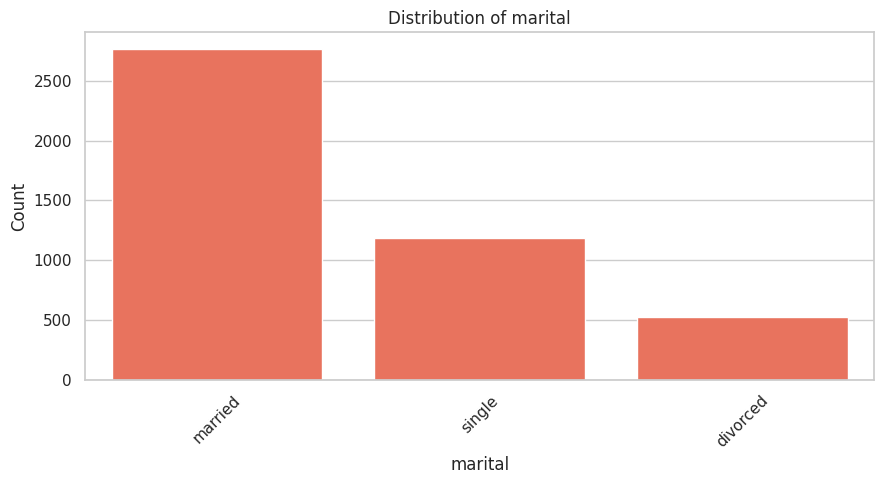

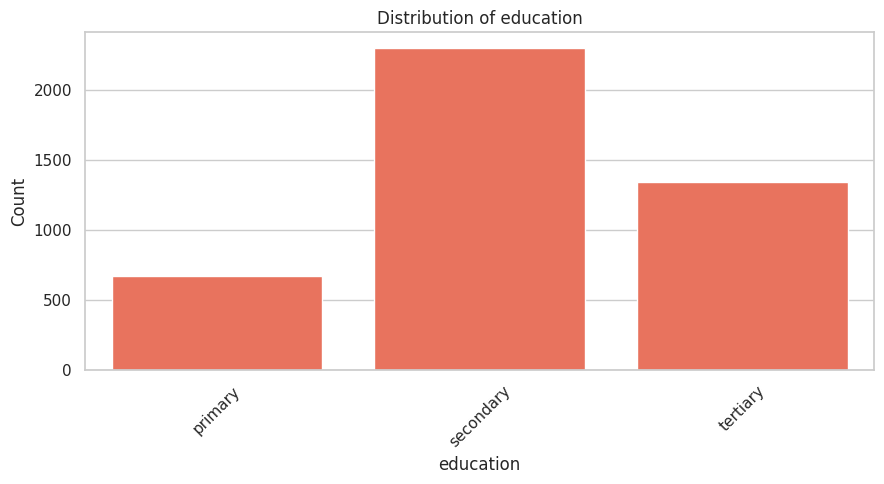

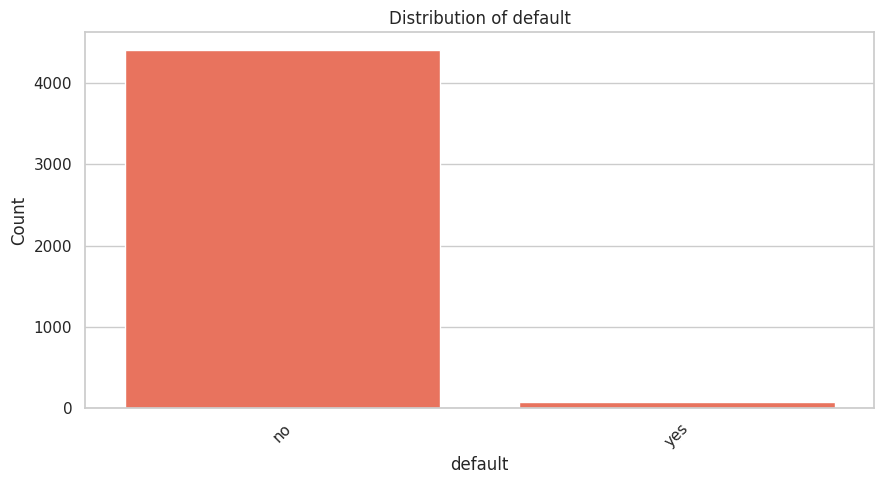

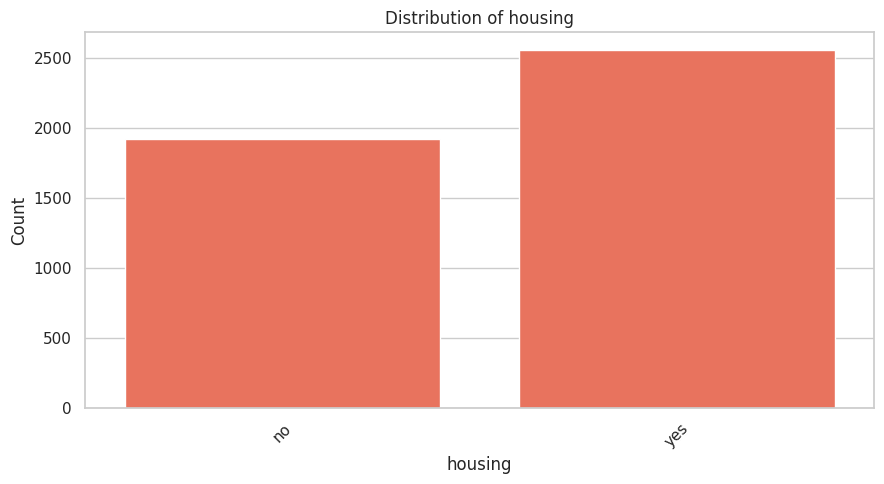

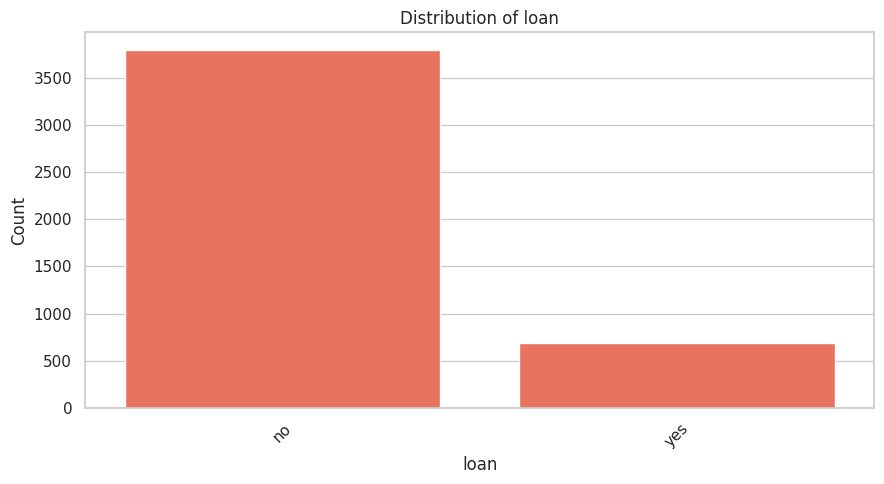

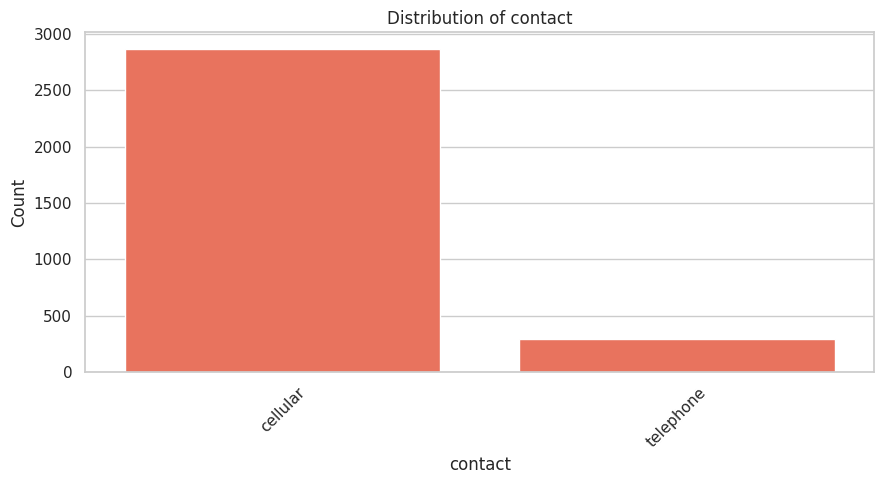

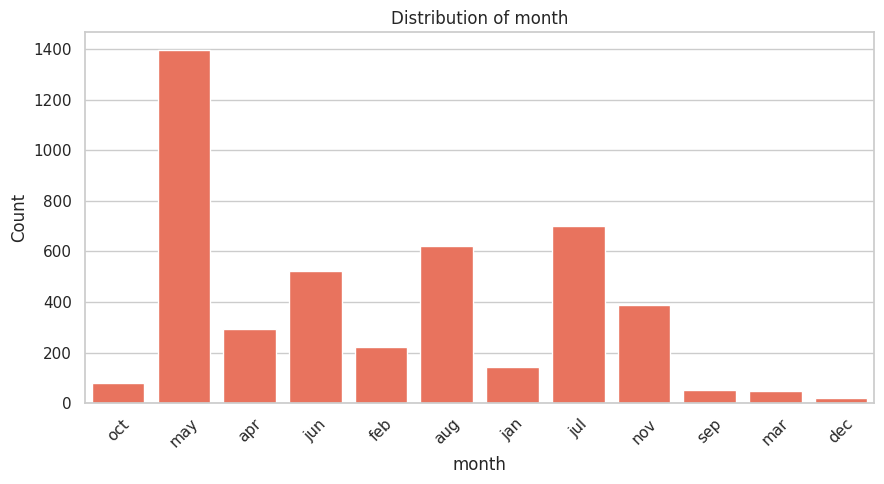

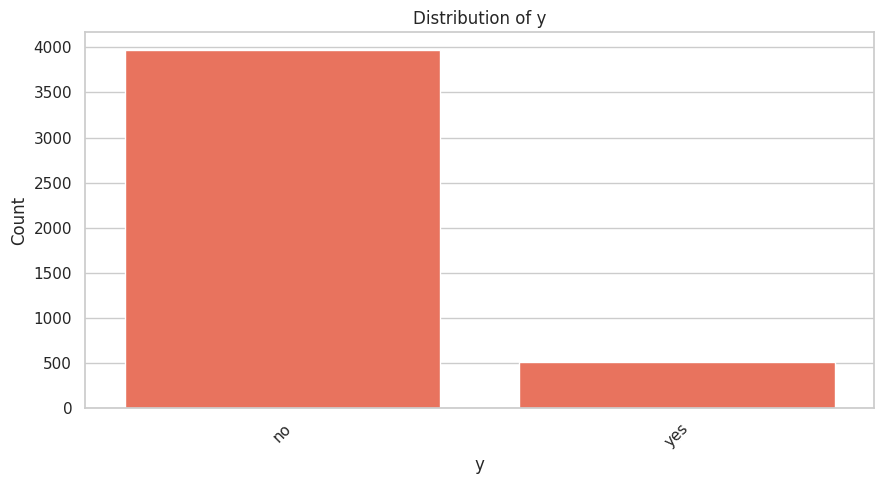

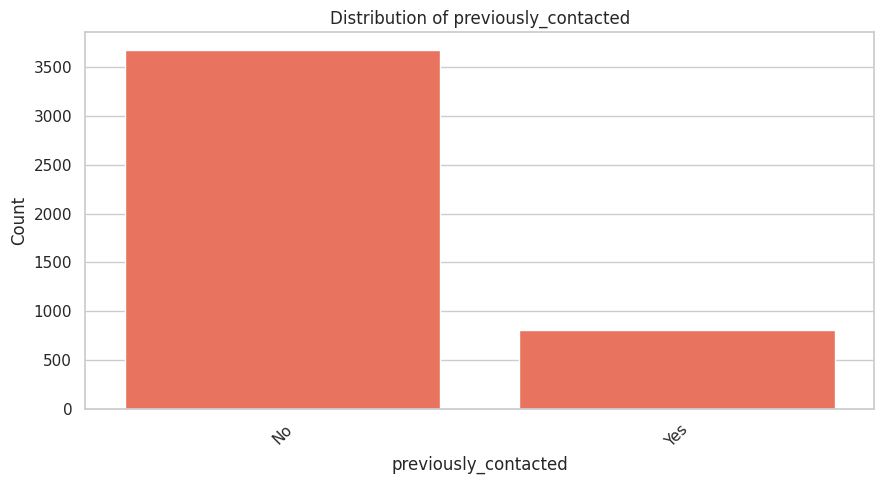

In [97]:
for col in cat_cols:

    plt.figure(figsize=(9, 5))

    # Creating count plot
    sns.countplot(data=df_bank,x=col,edgecolor="white",color = "tomato")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Feature and Target Separation

In [98]:
X = df_bank.drop(columns=["y"])
y = df_bank["y"]

Data Leakage presents in duration column

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#**Member 3- Kevin Biju Kulangara** - Data Preprocessing

###Separating numerical and categorical columns

In [100]:
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

In [101]:
num_cols

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')

In [102]:
cat_cols

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'previously_contacted'],
      dtype='object')

##Numerical Data Preprocessing

###Null value handling

In [103]:
X_train[num_cols].isna().sum()

,0
age,0
balance,0
day,0
duration,0
campaign,0
pdays,0
previous,0


In [104]:
X_test[num_cols].isna().sum()

,0
age,0
balance,0
day,0
duration,0
campaign,0
pdays,0
previous,0


###Outliers Handling

In [105]:
X_train_num = pd.DataFrame(
    X_train,
    columns=num_cols,
    index = X_train.index
)

X_test_num = pd.DataFrame(
    X_test,
    columns=num_cols,
    index = X_test.index
)

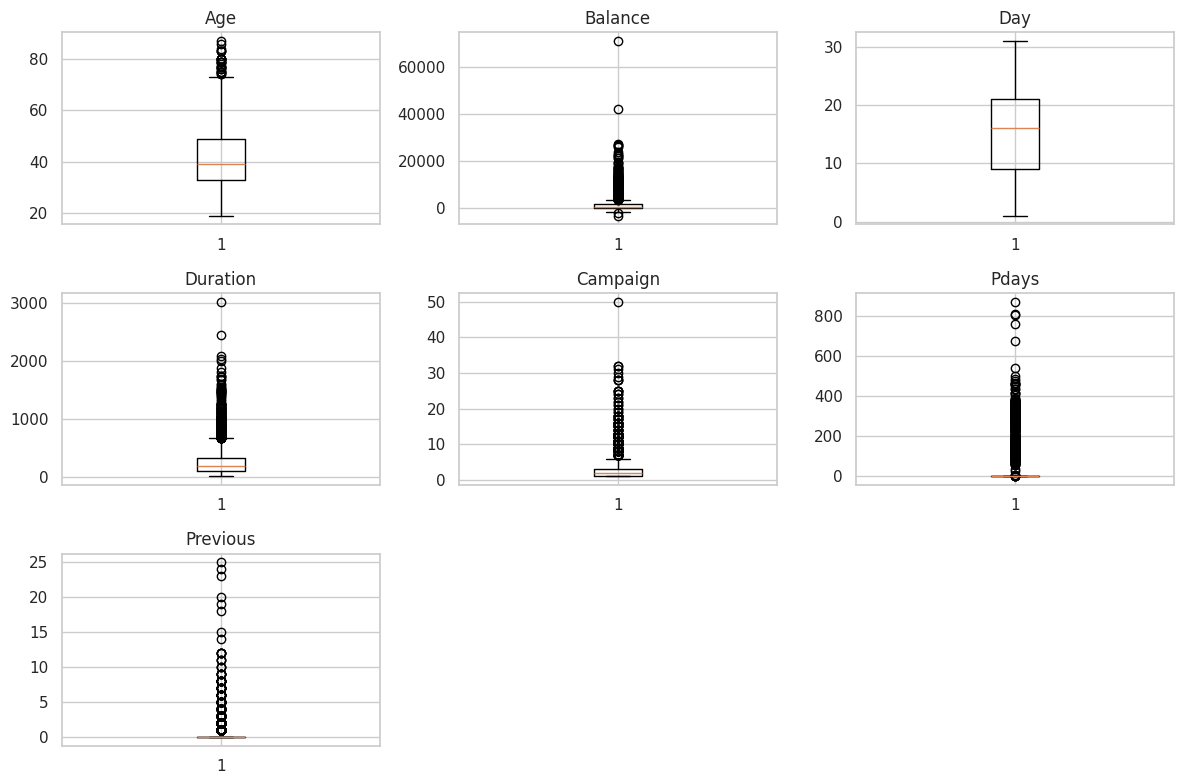

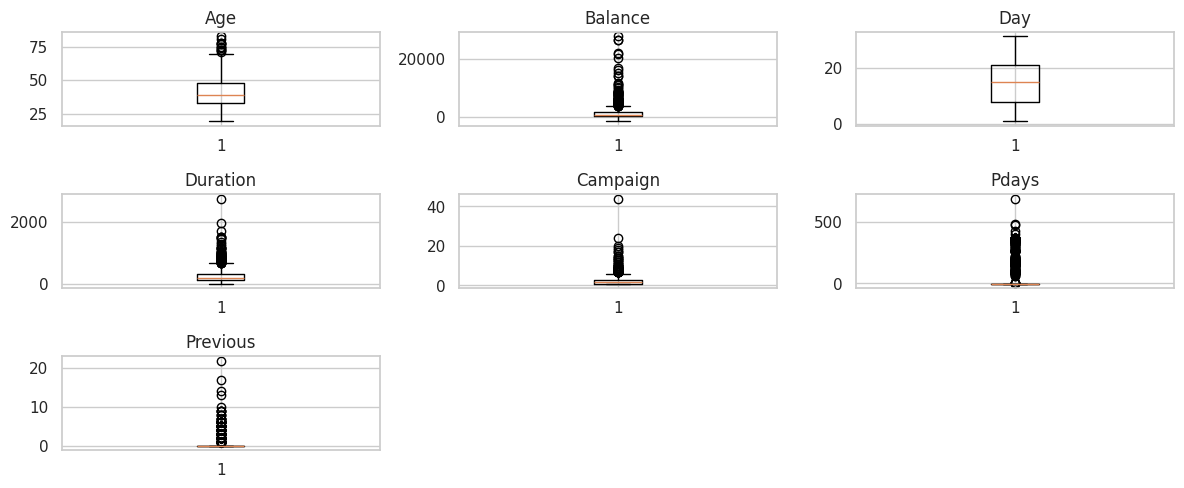

In [106]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    plt.boxplot(X_train_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(5, 3, i)
    plt.boxplot(X_test_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

In [107]:
def Outliers_handling(data):
  Q1 = data[num_cols].quantile(0.25)
  Q3 = data[num_cols].quantile(0.75)

  IQR = Q3 - Q1

  lower_limit = Q1 - 1.5 * IQR
  upper_limit = Q3 + 1.5 * IQR

  return (lower_limit, upper_limit)

lower, upper = Outliers_handling(X_train)

print(lower)
print("---------------------")
print(upper)

X_train_num[num_cols] = X_train_num[num_cols].clip(lower=lower, upper=upper, axis=1)
X_test_num[num_cols] = X_test_num[num_cols].clip(lower=lower, upper=upper, axis=1)

age            9.000
balance    -2051.625
day           -9.000
duration    -232.500
campaign      -2.000
pdays         -1.000
previous       0.000
dtype: float64
---------------------
age           73.000
balance     3601.375
day           39.000
duration     667.500
campaign       6.000
pdays         -1.000
previous       0.000
dtype: float64


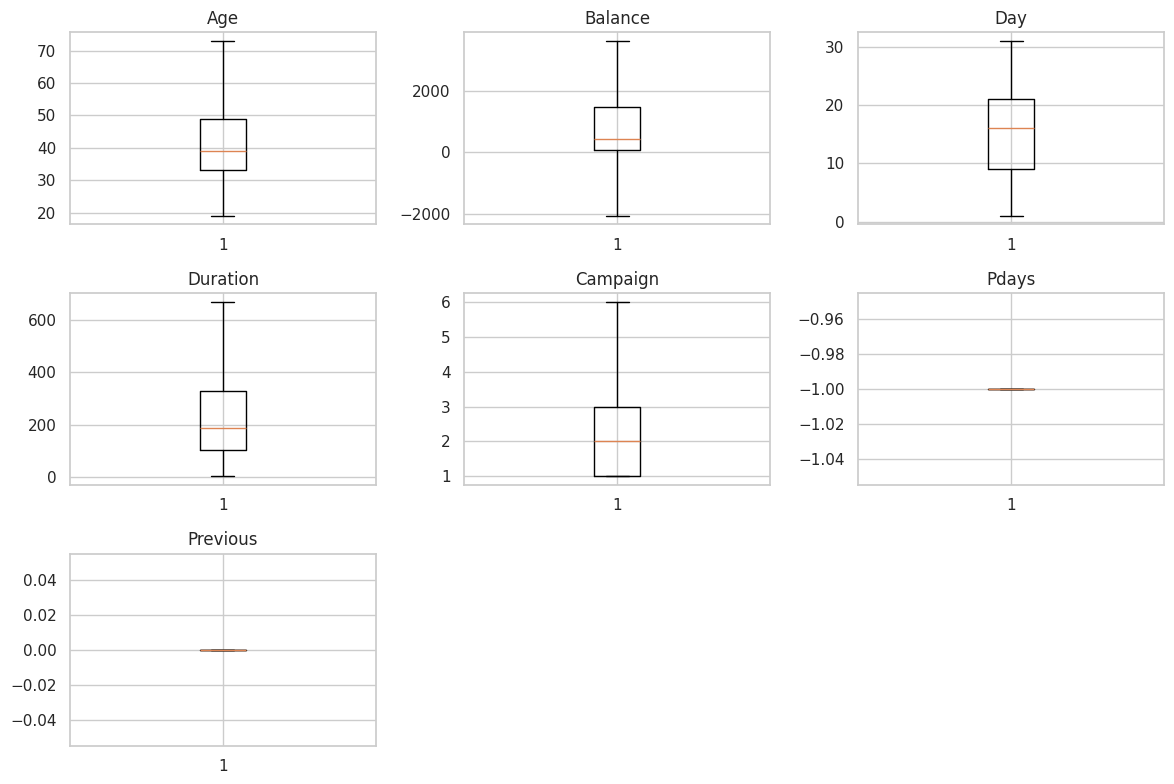

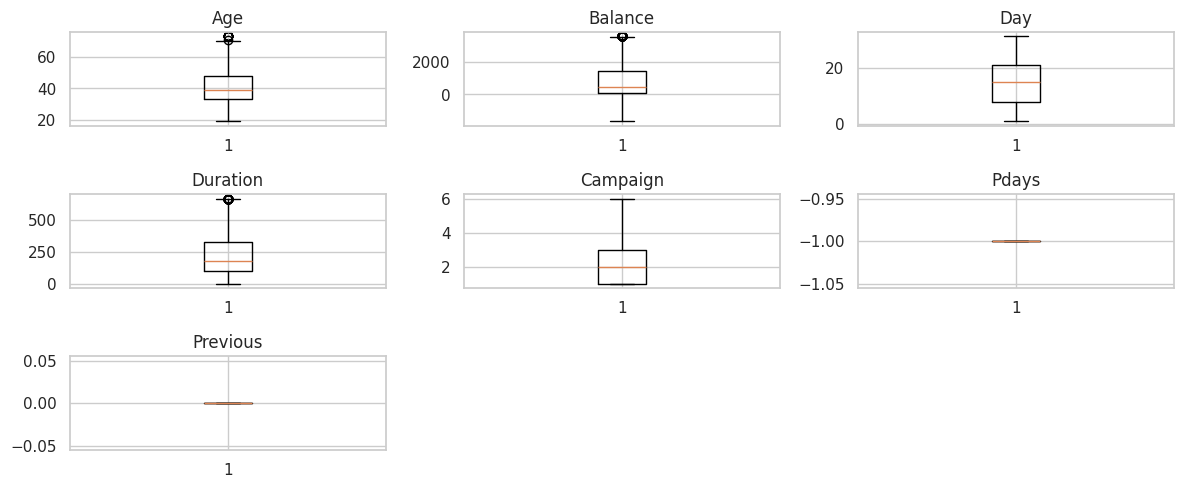

In [108]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    plt.boxplot(X_train_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(5, 3, i)
    plt.boxplot(X_test_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

###Standard Scalaing

In [109]:
scaler = StandardScaler()
X_train_num_scale = scaler.fit_transform(X_train_num)
X_test_num_scale = scaler.transform(X_test_num)

##Categorical Data Preprocessing

###Missing value Handling

In [110]:
print(X_train[cat_cols].isna().sum())

job                        0
marital                    0
education                135
default                    0
housing                    0
loan                       0
contact                 1052
month                      0
previously_contacted       0
dtype: int64


In [111]:
print(X_test[cat_cols].isna().sum())

job                       0
marital                   0
education                37
default                   0
housing                   0
loan                      0
contact                 263
month                     0
previously_contacted      0
dtype: int64


In [112]:
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.fit_transform(X_test[cat_cols])

###Converting all numpy arrays to dataframes

In [113]:
X_train_num_scale = pd.DataFrame(
    X_train_num_scale,
    columns=num_cols,
    index=X_train.index
)

X_test_num_scale = pd.DataFrame(
    X_test_num_scale,
    columns=num_cols,
    index=X_test.index
)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=cat_cols,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=cat_cols,
    index=X_test.index
)

###Encoding

In [114]:
for col in cat_cols:
  print(f"{col}: {X_train_cat[col].unique()}")

job: ['services' 'management' 'technician' 'student' 'blue-collar' 'retired'
 'self-employed' 'unemployed' 'admin.' 'housemaid' 'entrepreneur']
marital: ['married' 'single' 'divorced']
education: ['secondary' 'tertiary' 'primary']
default: ['no' 'yes']
housing: ['no' 'yes']
loan: ['no' 'yes']
contact: ['cellular' 'telephone']
month: ['jun' 'jul' 'aug' 'nov' 'may' 'jan' 'apr' 'oct' 'sep' 'feb' 'mar' 'dec']
previously_contacted: ['No' 'Yes']


In [115]:
col_ordinal = ["education", "month"]
col_onehot = [col for col in cat_cols if col not in col_ordinal]

####Ordinal Encoding

In [116]:
ordinal_encoder = OrdinalEncoder(
    categories = [
        ["primary", "secondary", "tertiary"],
        ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
    ]
)

X_train_ordinal = ordinal_encoder.fit_transform(X_train_cat[col_ordinal])
X_test_ordinal=ordinal_encoder.transform(X_test_cat[col_ordinal])

X_train_ordinal = pd.DataFrame(
    X_train_ordinal,
    columns=col_ordinal,
    index=X_train.index
)

X_test_ordinal = pd.DataFrame(
    X_test_ordinal,
    columns=col_ordinal,
    index=X_test.index
)

####Onehot Encoding

In [117]:
onehot_encoder = OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X_train_onehot = onehot_encoder.fit_transform(X_train_cat[col_onehot])

X_test_onehot = onehot_encoder.transform(X_test_cat[col_onehot])

onehot_names = onehot_encoder.get_feature_names_out(col_onehot)

X_train_onehot = pd.DataFrame(
    X_train_onehot,
    columns=onehot_names,
    index=X_train.index
)

X_test_onehot = pd.DataFrame(
    X_test_onehot,
    columns=onehot_names,
    index=X_test.index
)

####Concatinating Ordinal and Onehot dataframes

In [118]:
X_train_encoded = pd.concat(
    [X_train_onehot, X_train_ordinal],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_onehot, X_test_ordinal],
    axis=1
)

####Concatinating numeric and encoded columns

In [119]:
X_train_final = pd.concat(
    [X_train_num_scale, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num_scale, X_test_encoded],
    axis=1
)

####Label Encoding

In [120]:
print(y_train.value_counts())

y
no     3175
yes     411
Name: count, dtype: int64


In [121]:
y_train = y_train.map({'no': 0, 'yes': 1})
y_test = y_test.map({'no': 0, 'yes': 1})

In [122]:
print(y_train.value_counts())

y
0    3175
1     411
Name: count, dtype: int64


#**Member 4- Sharon** Class Balancing and Feature Selection

##